**How Do We Deal with More Complex Spectra?**

As has been shown in [the previous notebook](http://localhost:8888/lab/tree/Introduction%20to%20the%20Pade%20Transform.ipynb), the Pade transform can be an incredibly powerful tool for reconstructing spectra from a highly truncated starting point. Though the initial example works well as a proof of concept, real spectra are often more difficult. We have many resonances which are close together, often with a relatively low signal-to-noise ratio. The Pade transform is well suited to dealing with these problems. In this notebook, we will show how we can use an overdetermined system to solve and retain numerical stability in significantly more complex spectra, comparing different methods of solution, and demonstrating the use of the Pade transform as a noise filter; identifying and removing artefacts in the complex plane and transforming back to get a cleaner signal. For the sake of time and legibility, several functions will be imported here, with any new functions and modifications separately highlighted. As before, we wish to generate synthetic signals, with known values, though this time we will add noise.

In [2]:
import numpy as np
from numpy import random as rnd
from matplotlib import pyplot as plt

def generate_synthetic_decay(k, tmax, delta_t):
    """
    Generates a pseudo-random decay signal for any given k.
    """
    
    rnd.seed(k)

    fid = []

    amp, decay, phase = rnd.rand(3)
    freq = 20 * rnd.rand()
    d_k = amp * np.exp(complex(0,1) * phase)
    
    for n in range(0, tmax):

        z_k = np.exp((-decay + (complex(0,1) * 2 * np.pi * freq)) * n * delta_t)
        fid.append(d_k * z_k)

    return fid
          

def generate_synthetic_signal(elements, noise_level=0, tmax=1000, delta_t=0.01):
    """
    We take a number of elements and for each element produce a clean signal with pseudo-random parameters.
    These elements are then superposed into a single signal, which is what we will later decompose.
    The noise level specifies how much noise to add to the final signal.
    """

    signal = np.zeros(tmax, dtype = complex)

    for element in range(elements):
        signal = np.add(signal, generate_synthetic_decay(element, tmax, delta_t))

    real_noise = noise_level * rnd.normal(size = tmax)
    complex_noise = 1j* noise_level * rnd.normal(size = tmax)

    signal = np.add(signal, real_noise)
    signal = np.add(signal, complex_noise)

    return signal

Formulating the signals like this lets us test out the accuracy of the Pade transform on noisier signals, or signals with more elements, and look at how and where the Pade transform breaks. 

Let's re-implement our Pade transform and see how well it works on noisier, and busier, signals. 

In [48]:
def pade_solve(signal, elements, datapoints, tmax=1000, delta_t=0.01, svd=False):
    """
    Given a signal and the number of elements to decompose into, this uses the Pade techniques detailed in the previous notebook 
    to reconstruct (and return) the original signals. 
    """

    signal_used = signal[:datapoints].tolist()
    empty_matrix = []
    rhs_vector = []

    for i in range(datapoints - elements):
        matrix_row = signal_used[i:elements+i]
        matrix_row.reverse()
        empty_matrix.append(matrix_row)
        rhs_vector.append( -1 * signal_used[elements+i])

    matrix = np.array(empty_matrix, dtype=complex)
    rhs_vector = np.array(rhs_vector, dtype=complex)

    scales = np.linalg.norm(matrix, axis = 0)
    matrix_scaled = matrix / scales

    if svd == True:

        U, s, Vh = np.linalg.svd(matrix_scaled, full_matrices=False)
        threshold = 1e-15 * s[0]
        s_inv = np.array([1 / value if value > threshold else 0 for value in s])
        q_k_scaled = Vh.conj().T @ np.diag(s_inv) @ U.conj().T @ rhs_vector
    
    else:

        q_k_scaled, _, _, _ = np.linalg.lstsq(matrix_scaled, rhs_vector, rcond=None)

    q_k = q_k_scaled / scales

    coefficients = np.append(q_k[::-1], 1)
    roots = np.roots(coefficients)

    z_k = [(1 / root) for root in roots]

    empty_matrix = []
    rhs_vector = []

    for i in range(datapoints):
        matrix_row = [z**i for z in z_k]
        empty_matrix.append(matrix_row)
        rhs_vector.append(signal[i])

    matrix = np.array(empty_matrix, dtype=complex)
    rhs_vector = np.array(rhs_vector, dtype=complex)

    scales = np.linalg.norm(matrix, axis = 0)
    matrix_scaled = matrix / scales

    if svd == True:

        U, s, Vh = np.linalg.svd(matrix_scaled, full_matrices=False)
        threshold = 1e-15 * s[0]
        s_inv = np.array([1 / value if value > threshold else 0 for value in s])
        d_k_scaled = Vh.conj().T @ np.diag(s_inv) @ U.conj().T @ rhs_vector
    
    else:

        d_k_scaled, _, _, _ = np.linalg.lstsq(matrix_scaled, rhs_vector, rcond=None)

    d_k = d_k_scaled / scales

    mag = np.abs(z_k)
    arg = np.angle(z_k, deg=False)

    Lambda = - (np.log(mag)) / delta_t
    Frequency = arg / (2*np.pi*delta_t)

    Amplitude = np.abs(d_k)
    Phase = np.angle(d_k, deg=False)

    assert len(z_k) == len(d_k)

    individual_signals = []

    for z, d in zip(z_k, d_k):

        signal = []

        for n in range(tmax):
            signal.append(d * z**n)

        individual_signals.append(signal)

    individual_signals = np.array(individual_signals, dtype=complex)

    return individual_signals

signal = generate_synthetic_signal(elements=5, noise_level=0)
reconstructed = pade_solve(signal, elements=5, datapoints=10)

reconstructed_signal = np.sum(reconstructed, axis=0)

print("Maximum error:", np.max(np.abs(signal - reconstructed_signal)))

Maximum error: 5.0775872171568515e-05


Suggestively, this feature has some small changes and extra parameters when compared to our previous iteration. We can specify both the number of datapoints it recieves from the signal, as well as the number of elements we would like it to decompose the signal into. 

**Limitations of the Naive Pade Solver**

We have shown that on clean, no-noise signals made up of realtively few resonances, the Pade Transform performs exceptionally well on truncated data, needing only $2k$ datapoints in order to accurately replicate the signal. We will now look at how and where this breaks.

**Problem 1 - Many signals**

Let's see how well our solver can resolve signals made of an increasing number of resonances.

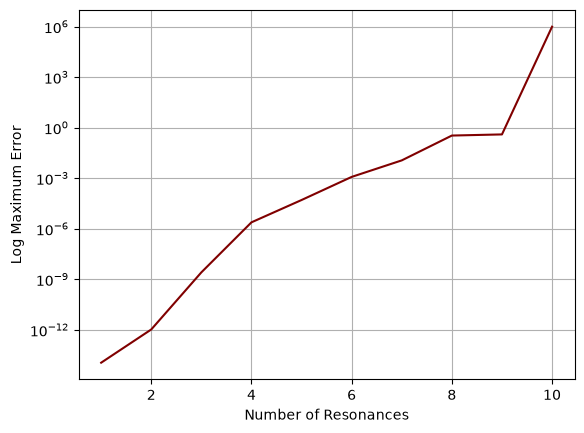

In [49]:
errors = []
maximum = 10

for resonances in range(1, maximum + 1):
    signal = generate_synthetic_signal(elements = resonances, noise_level = 0)
    reconstructed = pade_solve(signal, elements = resonances, datapoints = 2 * resonances)
    reconstructed_signal = np.sum(reconstructed, axis = 0)

    errors.append(np.max(np.abs(signal - reconstructed_signal)))

x = np.arange(1, maximum + 1)
y = errors

plt.plot(x, y, color='maroon')


plt.yscale('log')
plt.grid(True, which='both')


plt.xlabel(f"Number of Resonances")
plt.ylabel("Log Maximum Error")
plt.show()

As the number of resonances in the signal increases, the error in the reconstruction grows approximately exponentially in our current implementation. Why does this happen? The source of this error is three-fold: the instability of the matrix used to determine the $q_k$, the instability of the matrix used to determine the $d_k$, and the sensitivity of the polynomial roots used to recover the $\mathcal{z}_k$.

To understand this, it is first important to understand floating-point error and matrix conditioning. Computers cannot store arbitrary real numbers with infinite precision. Instead, standard double-precision floating-point numbers typically represent values to a relative precision of around $10^{-16}$. For most calculations this loss of precision is negligible, but in an ill-conditioned problem these very small errors can be greatly amplified.

As more resonances are added to the signal, the matrix used to determine the $q_k$ becomes increasingly ill-conditioned. The sampled signal is made up of terms of the form $\mathcal{z}_k^n$, and as the number of resonances increases (especially when the corresponding $\mathcal{z}_k$ lie close together) the different exponential components become increasingly difficult to distinguish numerically. We can quantify this sensitivity using the matrix condition number, $\kappa$. A large condition number means that very small perturbations in the sampled signal can produce much larger changes in the recovered $q_k$. A closely related problem occurs in the matrix used to determine the $d_k$, which also becomes increasingly ill-conditioned as the $\mathcal{z}_k$ become crowded.

The other major source of error occurs when we convert $q_k \rightarrow \mathcal{z}_k$. This requires finding the roots of the polynomial $\mathcal{Q}(w)$, which are highly sensitive to small errors in their coefficients, particularly when several roots lie close together. Consequently, a relatively small error in the $q_k$ can produce a much larger error in the recovered $\mathcal{z}_k$.

These errors are then amplified further during reconstruction. Each component contains a factor $\mathcal{z}_k^n$, so even a small error in $\mathcal{z}_k$ can become significant when raised to a large power. A tiny difference in $\mathcal{z}_k$ can lead to substantially different values by $n=1000$. Also, if numerical error pushes $|\mathcal{z}_k|$ above one, the reconstructed component can become exponentially growing rather than decaying, causing the reconstruction error to diverge dramatically.

Together, these effects mean that our current minimal Pade implementation is poorly suited to increasingly complex spectra containing many closely spaced resonances. 

So, how do we deal with this? We will attempt to deal with this in a few key ways: **overdetermination**, **normalisation**, and **SVD truncation**.

The most obvious (and most powerful) method for dealing with incresingly subtle and busier systems is called **overdetermination**. At current, we are using only the very minimum number of points we need to reconstruct the system: $2k$. By giving the solver more information than it technically "needs", we can restrict the solution space caused by these propagated floating point errors. Even by adding relatively few points, the amount of possible reconstructions that would approximate these well is ramatically reduced. This is the single msot powerful tool we have at our disposal for dealing with busier systems. Let's see how the error changes for a high number of resonances as we overdetermine the system.

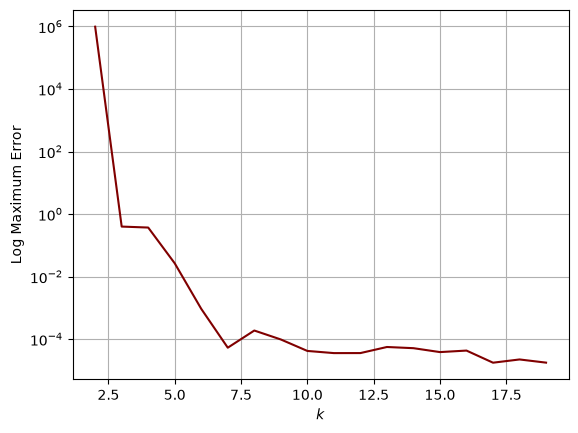

In [50]:
errors = []
resonances = 10
maximum = 20

for k in range(2, maximum):
    signal = generate_synthetic_signal(elements = resonances, noise_level = 0)
    reconstructed = pade_solve(signal, elements = resonances, datapoints = k * resonances)
    reconstructed_signal = np.sum(reconstructed, axis = 0)

    errors.append(np.max(np.abs(signal - reconstructed_signal)))

x = np.arange(2, maximum)
y = errors

plt.plot(x, y, color='maroon')


plt.yscale('log')
plt.grid(True, which='both')


plt.xlabel(f"$k$")
plt.ylabel("Log Maximum Error")
plt.show()

This is quite dramatic. Going from just $2k$ datapoints to $3k$ takes the maximum error from ~$10^8$ to <$1$. By ~$9k$ the maximum error starts to plateau at a level of <$10^{-4}$. This is the single most dramatic step we can take. It is not, however, the only step we can take. 

**Normalisation** is simple, and very cheap to implement- though the realtive difference it makes is small. Each time we solve a matrix equation $Aq = b$, the columns of $A$ can have dramatically different magnitudes. As we raise some of these to very high powers, then floating point errors can effect some columns more than others, making the overall solve weaker. By normaling each *column* in A and un-normalising after, we can remove this bias, making for a stronger solve. As adding this in is only a few lines, and does not meaningfully impact the computation time, it is a worthwhile implementation, even if it helps less.

**Singular Vector Decomposition (SVD)** is a very powerful tool, and one that can be used in multiple ways in order to better solve the matrix problems $Aq = b$. We will discuss two approaches here: the truncated SVD, and the null vector approach. Both of these can be very powerful, and will help not jsut in busy systems, but evena s we begin to see how noise affects busy spectra. Let us detail the truncated SVD approach first.

Any normal, square matrix, with an orthonormal eigenbasis, can be decomposed into a canonical form given by $$A = Q^{-1}DQ$$ Where $D$ is a diagonal matrix. An SVD generalises this to any $m \times n$ matrix. Geometrically, it is equivalent to saying the effect of any matrix on a basis, is equivalent to a rotation, followed by a scaling, followed by another rotation. Specifically, any matrix $\textbf{M}$ can be decomposed into: $$\textbf{M} = \textbf{U}  \Sigma  \textbf{V}^*$$

Where $\textbf{V}^*$ is a rotation, $\Sigma$ is a scaling, and **U** a second rotation. It is widely used across many areas of mathematics, but what is initially important is looking at the diagonal scaling matrix $\Sigma$. This is an $n \times n$ diagonal matrix composed of $n$ singular values, $\sigma$, which tells us how important a given direction is for the matrix, where tiny values correspond to a relatively small impact. When we solve $Aq = b$, we are really trying to solve $$q = A^{-1}b$$ Where $A^{-1}$ represents the pseudo-inverse. And using our SVD to decompose A this gives:
$$q = V \Sigma^{-1} U^* b$$

But taking $\Sigma^{-1}$ for a square diagonal matrix is equivalent to simply inverting the eignevalues. Each $\sigma_n \rightarrow \frac{1}{\sigma_n}$ means that these tiny amplitudes get amplified massively. Truncating the SVD refers to discarding these tiny values, where floating point errors will have an outsized impact, and can be a very powerful tool for helping to resolve busier/ noisier systems. 

Let's add this truncated SVD into our solver, and see how it impacts numerical stability.

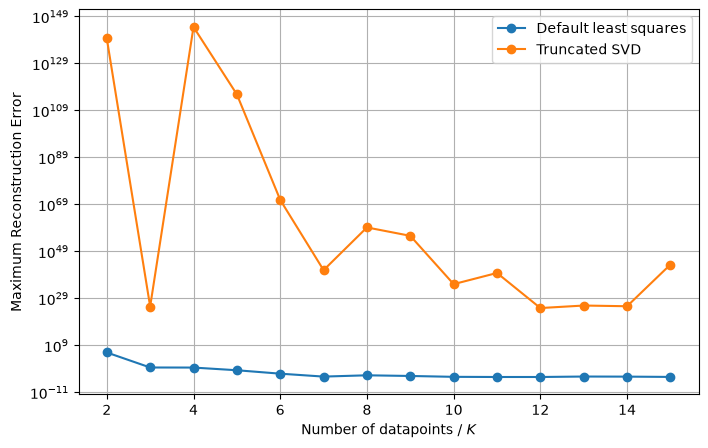

In [66]:
resonances = 10
maximum = 15

errors_default = []
errors_tsvd = []

signal = generate_synthetic_signal(elements=resonances,noise_level=0)

for k in range(2, maximum + 1):

    datapoints = k * resonances

    reconstructed = pade_solve(signal,elements=resonances,datapoints=datapoints,svd=False)
    reconstructed_signal = np.sum(reconstructed, axis=0)

    errors_default.append(np.max(np.abs(signal - reconstructed_signal)))

    reconstructed = pade_solve(signal,elements=resonances,datapoints=datapoints,svd=True)
    reconstructed_signal = np.sum(reconstructed, axis=0)

    errors_tsvd.append(np.max(np.abs(signal - reconstructed_signal)))

x = np.arange(2, maximum + 1)

plt.figure(figsize=(8, 5))

plt.plot(x, errors_default, marker='o', label="Default least squares")
plt.plot(x, errors_tsvd, marker='o', label="Truncated SVD")

plt.yscale("log")
plt.grid(True, which="both")

plt.xlabel(r"Number of datapoints / $K$")
plt.ylabel("Maximum Reconstruction Error")

plt.legend()
plt.show()

This is a significant finding. SVD does not, by default, improve accuracy, and especially not on noise-free systems. It can throw away genuinely useful information needed to determine a system